<a href="https://colab.research.google.com/github/hridayrjain/BIS-Lab/blob/main/1BM24CS119_%20Robotics%20and%20automation_%20Cuckoo%20Search.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Hriday R Jain

---

1BM24CS119

Application: Robotics and automation

Problem statement: An autonomous robot must travel from a starting position to a
target position in an environment containing obstacles. Develop a CS algorithm to
optimize the robot&#39;s path while avoiding collisions and minimizing travel distance.

Objective: Find a feasible collision-free path with minimum length or travel time.

Running Cuckoo Search Optimization Core Engine...
Optimization finished. Best Path Cost: 144.90


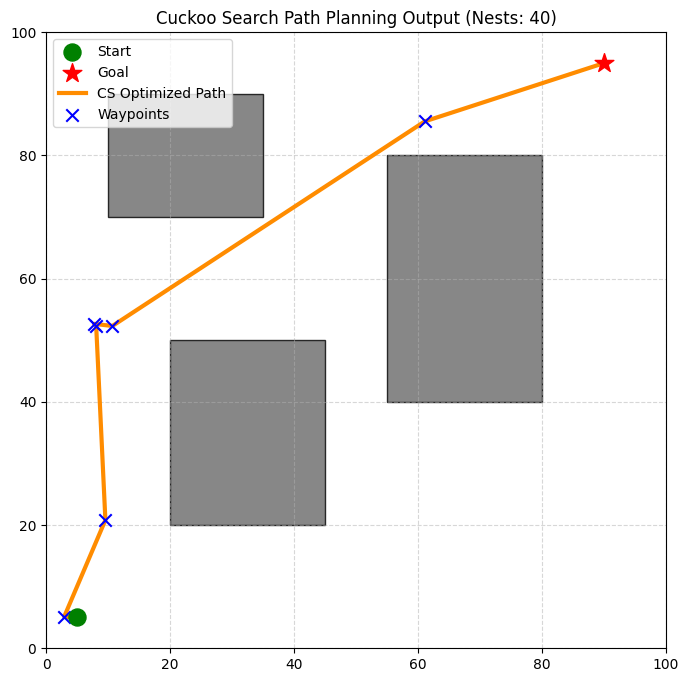

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma

class CuckooSearchPathPlanner:
    def __init__(self, start, goal, obstacles, n_nests=30, max_iter=100, n_way=5, grid_size=(100, 100), pa=0.25, penalty=1000):
        """
        Standalone Cuckoo Search (CS) for Robot Path Planning in a 2D Grid.
        Based on the classic CS steps: Levy Flights + Abandoning Worst Nests (Pa).
        """
        self.start = np.array(start, dtype=float)
        self.goal = np.array(goal, dtype=float)
        self.obstacles = obstacles
        self.n_nests = n_nests
        self.max_iter = max_iter
        self.n_way = n_way
        self.grid_size = grid_size
        self.pa = pa
        self.penalty = penalty

        # 2D coordinates for each waypoint (x, y)
        self.dim = n_way * 2

        # Step 3: Initialize population of nests randomly inside workspace bounds
        self.nests = np.random.uniform(0, max(grid_size), (self.n_nests, self.dim))
        self.fitness_values = np.zeros(self.n_nests)

        # Track global best nest
        self.best_nest = np.zeros(self.dim)
        self.best_fitness = float('inf')

        # Lévy flight parameters (Mantegna's algorithm constants)
        self.beta = 1.5
        self.sigma_u = self._calculate_sigma()

    def _calculate_sigma(self):
        """Calculates standard deviation parameter for Mantegna's Lévy Flight algorithm."""
        num = gamma(1 + self.beta) * np.sin(np.pi * self.beta / 2)
        den = gamma((1 + self.beta) / 2) * self.beta * (2 ** ((self.beta - 1) / 2))
        return (num / den) ** (1 / self.beta)

    def _reconstruct_path(self, nest_i):
        """Step 1: Path(X) = START + waypoints in X + GOAL"""
        waypoints = nest_i.reshape((self.n_way, 2))
        return np.vstack([self.start, waypoints, self.goal])

    def _line_intersects_box(self, p1, p2, box):
        """Calculates collision penetration depth against a rectangular obstacle."""
        if (max(p1[0], p2[0]) < box['x_min'] or min(p1[0], p2[0]) > box['x_max'] or
            max(p1[1], p2[1]) < box['y_min'] or min(p1[1], p2[1]) > box['y_max']):
            return 0.0

        samples = 15
        collision_depth = 0.0
        for t in np.linspace(0, 1, samples):
            pt = p1 + t * (p2 - p1)
            if (box['x_min'] <= pt[0] <= box['x_max']) and (box['y_min'] <= pt[1] <= box['y_max']):
                center_x = (box['x_min'] + box['x_max']) / 2.0
                center_y = (box['y_min'] + box['y_max']) / 2.0
                dist_to_center = np.linalg.norm(pt - np.array([center_x, center_y]))
                collision_depth += max(0.1, 10.0 / (dist_to_center + 0.1))
        return collision_depth

    def fitness(self, nest_i):
        """Step 1 & 4: Evaluate Objective Fitness Function f(x)"""
        path = self._reconstruct_path(nest_i)
        length = np.sum(np.sqrt(np.sum(np.diff(path, axis=0)**2, axis=1)))

        total_collision_depth = 0.0
        for i in range(len(path) - 1):
            for obs in self.obstacles:
                total_collision_depth += self._line_intersects_box(path[i], path[i+1], obs)

        return length + (self.penalty * total_collision_depth)

    def _levy_flight(self, current_nest):
        """Step 5: Generate new solutions using Mantegna's Lévy Flight implementation"""
        u = np.random.normal(0, self.sigma_u, self.dim)
        v = np.random.normal(0, 1, self.dim)

        step = u / (np.abs(v) ** (1 / self.beta))
        step_size = 0.05 * step * (current_nest - self.best_nest)

        new_nest = current_nest + step_size * np.random.normal(0, 1, self.dim)
        return np.clip(new_nest, 0, max(self.grid_size))

    def optimize(self):
        # Initial population evaluation step
        for i in range(self.n_nests):
            self.fitness_values[i] = self.fitness(self.nests[i])
            if self.fitness_values[i] < self.best_fitness:
                self.best_fitness = self.fitness_values[i]
                self.best_nest = self.nests[i].copy()

        # Step 7: Main Iterative Loop
        for t in range(self.max_iter):

            # 1. Generate New Solutions via Lévy Flights (Step 5)
            for i in range(self.n_nests):
                new_nest = self._levy_flight(self.nests[i])
                new_fit = self.fitness(new_nest)

                # Keep better nests (Greedy selection strategy)
                if new_fit < self.fitness_values[i]:
                    self.nests[i] = new_nest
                    self.fitness_values[i] = new_fit

            # 2. Abandon Worst Nests according to Pa probability (Step 6)
            sorted_indices = np.argsort(self.fitness_values)
            n_abandon = int(self.pa * self.n_nests)
            worst_indices = sorted_indices[-n_abandon:]

            for idx in worst_indices:
                # Random discovery walk mixing step implementation
                r1, r2 = np.random.choice(self.n_nests, 2, replace=False)
                step_factor = np.random.rand()

                new_nest = self.nests[idx] + step_factor * (self.nests[r1] - self.nests[r2])
                new_nest = np.clip(new_nest, 0, max(self.grid_size))

                self.nests[idx] = new_nest
                self.fitness_values[idx] = self.fitness(new_nest)

            # Update the global optimum tracker
            for i in range(self.n_nests):
                if self.fitness_values[i] < self.best_fitness:
                    self.best_fitness = self.fitness_values[i]
                    self.best_nest = self.nests[i].copy()

        # Step 8: Return final reconstructed optimal path configurations
        best_path = self._reconstruct_path(self.best_nest)
        return best_path, self.best_fitness

    def plot_path(self, best_path):
        """Visualizes the map configuration canvas overlaying final optimized path maps."""
        plt.figure(figsize=(8, 8))
        ax = plt.gca()

        for obs in self.obstacles:
            rect = plt.Rectangle((obs['x_min'], obs['y_min']),
                                 obs['x_max'] - obs['x_min'],
                                 obs['y_max'] - obs['y_min'],
                                 facecolor='dimgray', edgecolor='black', alpha=0.8)
            ax.add_patch(rect)

        plt.scatter(self.start[0], self.start[1], color='green', marker='o', s=150, label='Start', zorder=5)
        plt.scatter(self.goal[0], self.goal[1], color='red', marker='*', s=200, label='Goal', zorder=5)

        plt.plot(best_path[:, 0], best_path[:, 1], color='darkorange', linestyle='-', linewidth=3, label='CS Optimized Path')
        plt.scatter(best_path[1:-1, 0], best_path[1:-1, 1], color='blue', marker='x', s=80, label='Waypoints', zorder=4)

        plt.xlim(0, self.grid_size[0])
        plt.ylim(0, self.grid_size[1])
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.title(f"Cuckoo Search Path Planning Output (Nests: {self.n_nests})")
        plt.legend(loc='upper left')
        plt.show()

# --- Execution Entry Point ---
if __name__ == "__main__":
    start_pos = (5, 5)
    goal_pos = (90, 95)
    map_bounds = (100, 100)

    static_obstacles = [
        {'x_min': 20, 'x_max': 45, 'y_min': 20, 'y_max': 50},
        {'x_min': 55, 'x_max': 80, 'y_min': 40, 'y_max': 80},
        {'x_min': 10, 'x_max': 35, 'y_min': 70, 'y_max': 90}
    ]

    # Initialize Cuckoo Search Planner
    planner = CuckooSearchPathPlanner(
        start=start_pos,
        goal=goal_pos,
        obstacles=static_obstacles,
        n_nests=40,       # Number of nests (n)
        max_iter=150,     # Max iterations (MaxIter)
        n_way=6,          # Number of intermediate path waypoints
        pa=0.25,          # Discovery probability rate threshold
        grid_size=map_bounds
    )

    print("Running Cuckoo Search Optimization Core Engine...")
    path, fitness_score = planner.optimize()
    print(f"Optimization finished. Best Path Cost: {fitness_score:.2f}")

    planner.plot_path(path)
